In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [3]:
df = pd.read_csv("uber.csv")
print(df.head())
print(df.shape)

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [4]:
df = df.dropna()

df = df.drop(columns=["Unnamed: 0", "key"])

df = df[(df["fare_amount"] > 0) &
        (df["passenger_count"] > 0)]

print(df.isnull().sum())

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


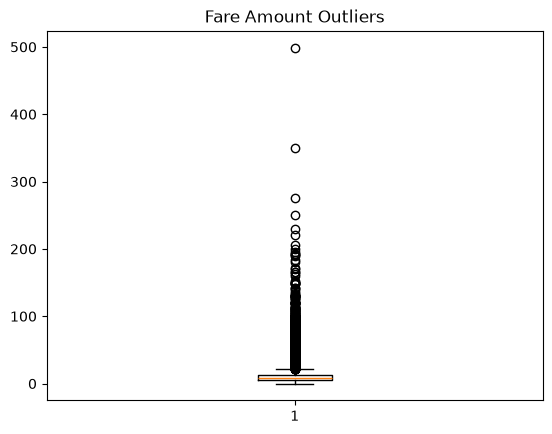

In [5]:
plt.boxplot(df["fare_amount"])
plt.title("Fare Amount Outliers")
plt.show()

In [6]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)
IQR = Q3 - Q1

df = df[(df['fare_amount'] >= Q1 - 1.5*IQR) &
        (df['fare_amount'] <= Q3 + 1.5*IQR)]

fare_amount          1.000000
pickup_longitude     0.000125
pickup_latitude      0.002826
dropoff_longitude   -0.002534
dropoff_latitude     0.000715
passenger_count      0.011995
Name: fare_amount, dtype: float64


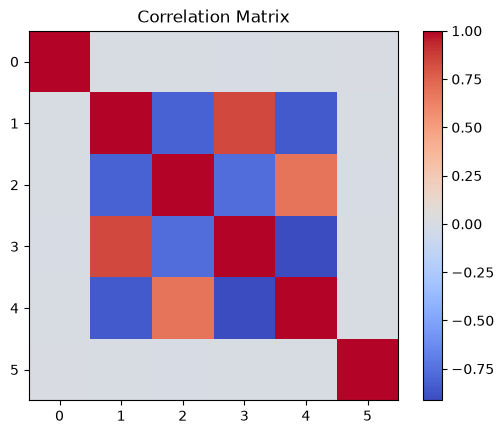

In [7]:

corr = df.corr(numeric_only=True)

print(corr["fare_amount"])

plt.imshow(corr, cmap="coolwarm")
plt.colorbar()
plt.title("Correlation Matrix")
plt.show()

In [8]:
X = df[["pickup_longitude", "pickup_latitude",
        "dropoff_longitude", "dropoff_latitude",
        "passenger_count"]]

y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Linear Regression")
print("R2:", r2_score(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
accuracy_lr = 100 - np.mean(np.abs((y_test - y_pred_lr) / y_test)) * 100
print("Accuracy:", accuracy_lr, "%")

Linear Regression
R2: 0.00013528305667731555
RMSE: 4.129226610295564
Accuracy: 55.84934190140928 %


In [10]:
rf = RandomForestRegressor(n_estimators=20, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest R2:", r2_score(y_test, y_pred_rf))
print("Random Forest RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))

Random Forest R2: 0.6922666840404008
Random Forest RMSE: 2.2907903978970876


In [11]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2': [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_rf)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ]
})

print(results)

               Model        R2      RMSE
0  Linear Regression  0.000135  4.129227
1      Random Forest  0.692267  2.290790
